# Week 4: Supervised Learning Model Implementation
## Bank Term Deposit Subscription Prediction

**Goal:** Predict whether a customer subscribes to a bank term deposit (`yes` / `no`).

**Dataset:** `bank_marketing_cleaned.csv` (expected 41,176 rows × 21 columns).

**Models:** Logistic Regression and Random Forest.

**Important:** `duration` is excluded because it is known only after the call. Including it would make a pre-call prediction unrealistic and introduce target leakage.

Run cells from top to bottom. Use the actual outputs from this notebook in your final report; do not invent performance values.

## 1. Import libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the cleaned dataset

In [2]:
file_name = "bank_marketing_cleaned.csv"
if not os.path.exists(file_name):
    raise FileNotFoundError(
        f"{file_name} was not found. Keep the CSV in the same folder as this notebook."
    )

df = pd.read_csv(file_name)
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (41176, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Inspect structure and data quality

In [3]:
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget counts:")
display(df["y"].value_counts(dropna=False))
print("\nTarget percentages:")
display((df["y"].value_counts(normalize=True) * 100).round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  object 
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  object 
 10  duration        41176 non-null  int64  
 11  campaign        41176 non-null  int64  
 12  pdays           41176 non-null  int64  
 13  previous        41176 non-null  int64  
 14  poutcome        41176 non-null  object 
 15  emp.var.rate    41176 non-null  float64
 16  cons.price.idx  41176 non-null  float64
 17  cons.conf.idx   41176 non-null 

,Missing Values
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


Total missing values: 0
Duplicate rows: 0

Target counts:


y
no     36537
yes     4639
Name: count, dtype: int64


Target percentages:


y
no     88.73
yes    11.27
Name: proportion, dtype: float64

### Data quality note
The Week 1 cleaned file is expected to contain 41,176 rows after removing 12 exact duplicates. Categorical values labelled `unknown` are not blank/null values; we retain them as explicit categories.

In [4]:
required_columns = {"y", "duration"}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")
if df["y"].isna().any():
    raise ValueError("Target column y contains missing values.")
print("Target labels:", sorted(df["y"].astype(str).str.lower().unique()))
print("Dataset dimensions:", df.shape)

Target labels: ['no', 'yes']
Dataset dimensions: (41176, 21)


## 4. Exploratory Data Analysis

### 4.1 Target class distribution

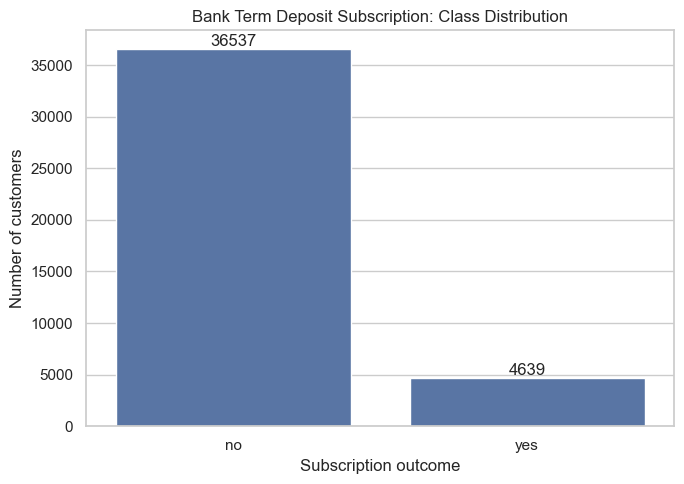

y
no     88.73
yes    11.27
Name: proportion, dtype: float64

In [5]:
target_counts = df["y"].value_counts().reindex(["no", "yes"])
plt.figure(figsize=(7, 5))
ax = sns.barplot(x=target_counts.index, y=target_counts.values)
ax.set_title("Bank Term Deposit Subscription: Class Distribution")
ax.set_xlabel("Subscription outcome")
ax.set_ylabel("Number of customers")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

display((df["y"].value_counts(normalize=True) * 100).round(2))

### 4.2 Numerical feature distributions

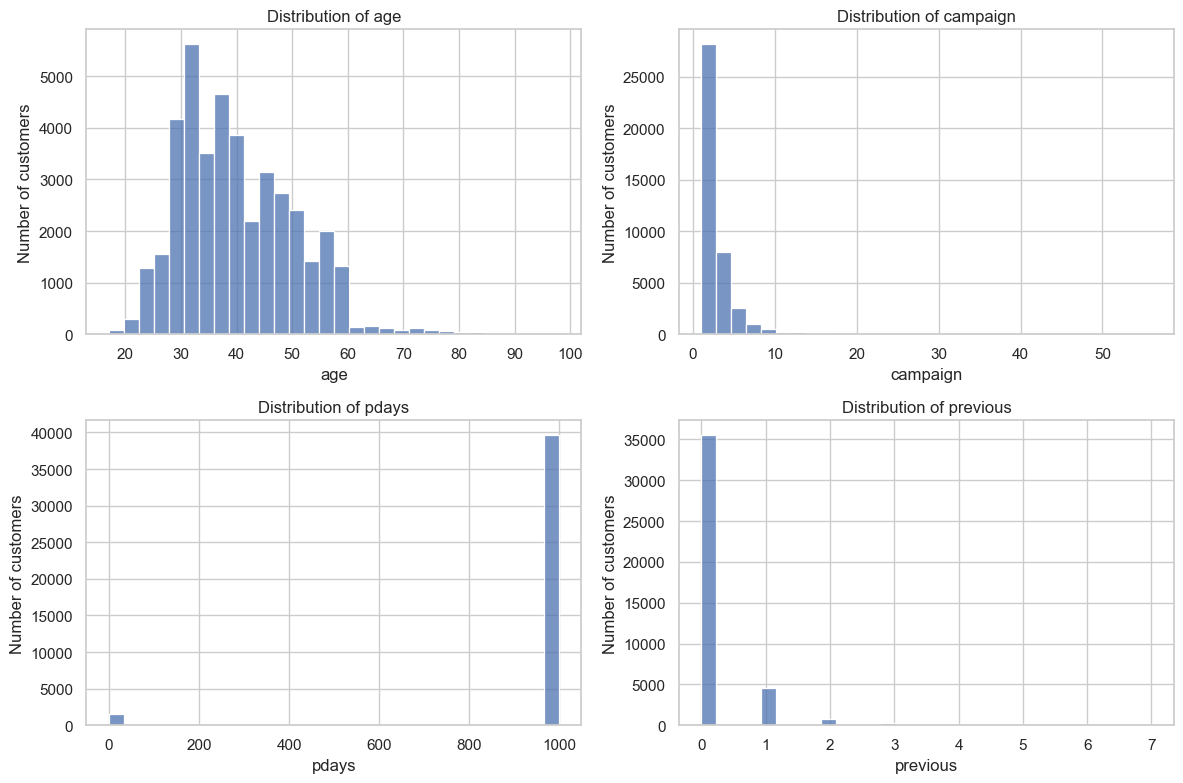

In [6]:
numeric_for_eda = ["age", "campaign", "pdays", "previous"]
available_numeric = [c for c in numeric_for_eda if c in df.columns]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for ax, col in zip(axes, available_numeric):
    sns.histplot(data=df, x=col, bins=30, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
for ax in axes[len(available_numeric):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### 4.3 Subscription rate by selected categorical features

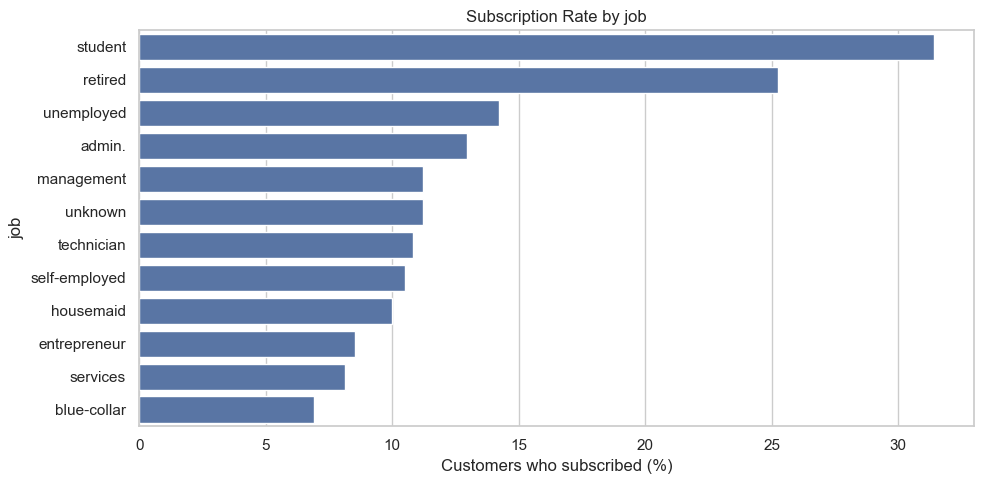

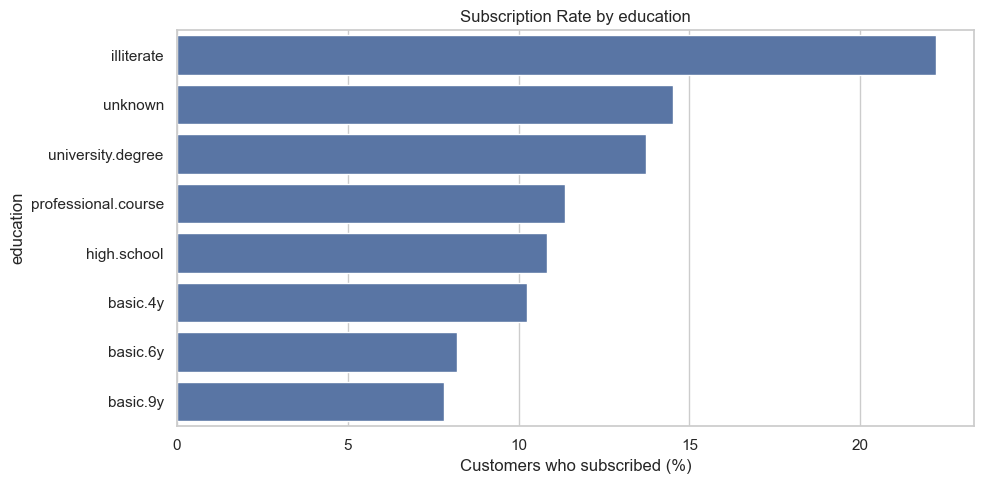

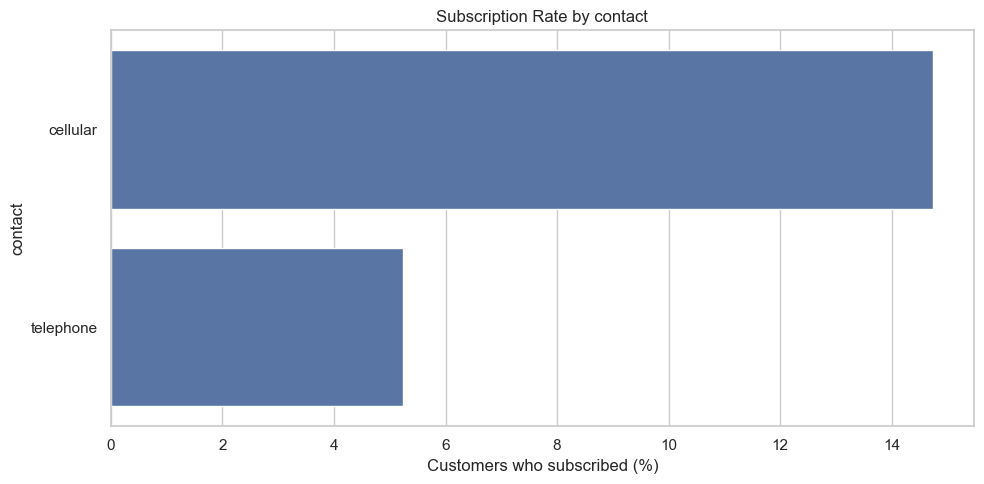

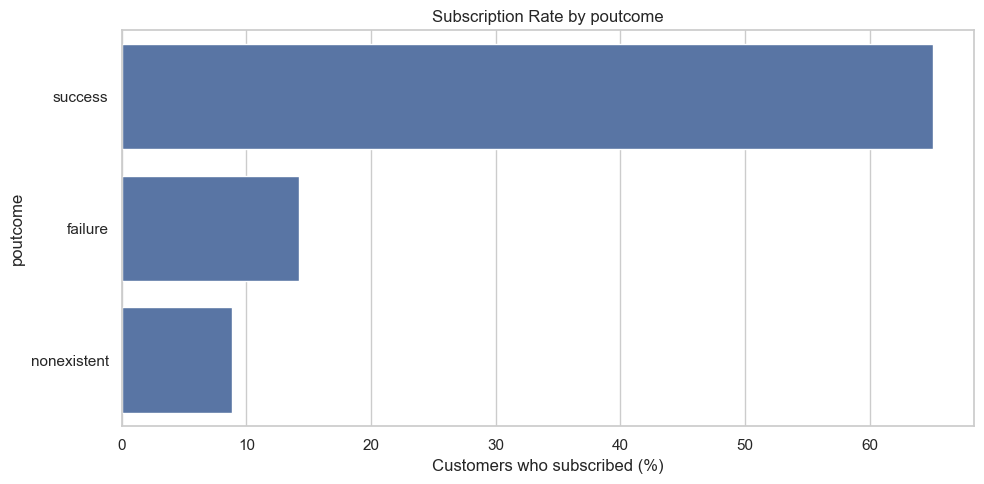

In [7]:
categorical_for_eda = ["job", "education", "contact", "poutcome"]
available_cats = [c for c in categorical_for_eda if c in df.columns]
for col in available_cats:
    rate = df.groupby(col, dropna=False)["y"].apply(
        lambda values: (values == "yes").mean() * 100
    ).sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=rate.values, y=rate.index)
    plt.title(f"Subscription Rate by {col}")
    plt.xlabel("Customers who subscribed (%)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## 5. Prepare predictors and target

This is a binary classification task: `no` = 0 and `yes` = 1. We exclude `duration` because it is only known after the call. The intended prediction is made before contacting the customer. The target column `y` is also excluded from predictors.

In [8]:
before_rows = len(df)
df = df.drop_duplicates().copy()
print("Duplicate rows removed in this notebook:", before_rows - len(df))

y = df["y"].astype(str).str.strip().str.lower().map({"no": 0, "yes": 1})
if y.isna().any():
    raise ValueError("Unexpected target labels found in y.")
y = y.astype(int)
X = df.drop(columns=["y", "duration"])

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(y.value_counts().rename(index={0: "no", 1: "yes"}))

Duplicate rows removed in this notebook: 0
Feature matrix shape: (41176, 19)
Target shape: (41176,)


y
no     36537
yes     4639
Name: count, dtype: int64

## 6. Stratified train-test split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename(index={0: "no", 1: "yes"}).round(4))
print("\nTesting target proportions:")
display(y_test.value_counts(normalize=True).rename(index={0: "no", 1: "yes"}).round(4))

Training shape: (32940, 19)
Testing shape: (8236, 19)

Training target proportions:


y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


Testing target proportions:


y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64

## 7. Preprocessing pipeline

Numerical features are median-imputed and standardized. Categorical features are imputed with the most frequent value and one-hot encoded. Preprocessing is inside each model pipeline, so it is fitted only on the relevant training fold during cross-validation.

In [10]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


## 8. Define the classification models

In [11]:
logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ))
])

random_forest_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ))
])
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}
print("Models defined:", list(models.keys()))

Models defined: ['Logistic Regression', 'Random Forest']


## 9. Cross-validation on training data

Three-fold stratified cross-validation is performed on the training set only. ROC-AUC and average precision help assess ranking performance when the positive class is uncommon. The test set is kept aside for final evaluation.

In [12]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "f1": "f1"
}
cv_results = {}
for model_name, model in models.items():
    print(f"Running cross-validation for {model_name}...")
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    cv_results[model_name] = {
        "CV ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "CV ROC-AUC Std": scores["test_roc_auc"].std(),
        "CV Average Precision Mean": scores["test_average_precision"].mean(),
        "CV F1 Mean": scores["test_f1"].mean()
    }
cv_summary = pd.DataFrame(cv_results).T.sort_values(
    "CV ROC-AUC Mean", ascending=False
)
display(cv_summary.round(4))

Running cross-validation for Logistic Regression...
Running cross-validation for Random Forest...


,CV ROC-AUC Mean,CV ROC-AUC Std,CV Average Precision Mean,CV F1 Mean
Logistic Regression,0.7899,0.0029,0.4447,0.4500
Random Forest,0.7823,0.0044,0.4482,0.4822


## 10. Fit both models on the full training set

In [13]:
for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
print("Both models trained successfully.")

Training Logistic Regression...
Training Random Forest...
Both models trained successfully.


## 11. Select a model using cross-validation

In [14]:
best_model_name = cv_summary.index[0]
best_model = models[best_model_name]
print("Selected model:", best_model_name)
print("Mean CV ROC-AUC:", round(cv_summary.loc[best_model_name, "CV ROC-AUC Mean"], 4))

Selected model: Logistic Regression
Mean CV ROC-AUC: 0.7899


## 12. Compare both models on the held-out test set

In [15]:
test_results = []
for model_name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision (yes)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (yes)": recall_score(y_test, y_pred, zero_division=0),
        "F1-score (yes)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob)
    })
test_summary = pd.DataFrame(test_results).set_index("Model")
display(test_summary.round(4))

,Accuracy,Balanced Accuracy,Precision (yes),Recall (yes),F1-score (yes),ROC-AUC,Average Precision
Model,,,,,,,
Logistic Regression,0.8303,0.7496,0.3591,0.6455,0.4615,0.8002,0.4463
Random Forest,0.8866,0.7141,0.4967,0.4914,0.4940,0.7983,0.4716


## 13. Detailed evaluation of the selected model

In [16]:
best_y_pred = best_model.predict(X_test)
best_y_prob = best_model.predict_proba(X_test)[:, 1]
print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_y_pred, target_names=["No subscription", "Subscription"],
    zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, best_y_prob), 4))
print("Average Precision:", round(average_precision_score(y_test, best_y_prob), 4))

Selected model: Logistic Regression

Classification report:
                 precision    recall  f1-score   support

No subscription       0.95      0.85      0.90      7308
   Subscription       0.36      0.65      0.46       928

       accuracy                           0.83      8236
      macro avg       0.65      0.75      0.68      8236
   weighted avg       0.88      0.83      0.85      8236

ROC-AUC: 0.8002
Average Precision: 0.4463


## 14. Confusion matrix

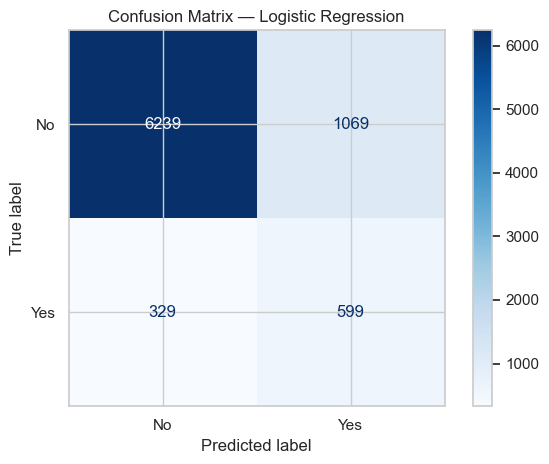

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test, best_y_pred, display_labels=["No", "Yes"],
    cmap="Blues", values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 15. ROC and Precision-Recall curves

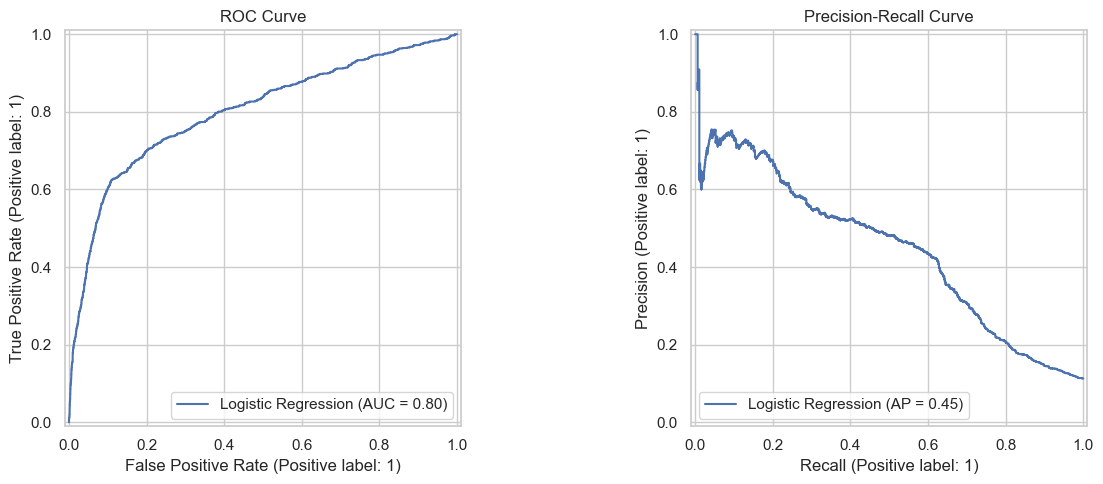

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, best_y_prob, ax=axes[0], name=best_model_name)
axes[0].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, best_y_prob, ax=axes[1], name=best_model_name)
axes[1].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

## 16. Random Forest feature importance

Feature importance is shown for Random Forest even if Logistic Regression is selected as the best model. Importance values describe how the Random Forest model used the transformed features; they do not establish causation.

,Feature,Importance
7,num__euribor3m,0.138503
0,num__age,0.112080
8,num__nr.employed,0.065741
1,num__campaign,0.062162
4,num__emp.var.rate,0.059405
6,num__cons.conf.idx,0.037737
5,num__cons.price.idx,0.030031
2,num__pdays,0.026644
61,cat__poutcome_success,0.021321
38,cat__housing_yes,0.016694


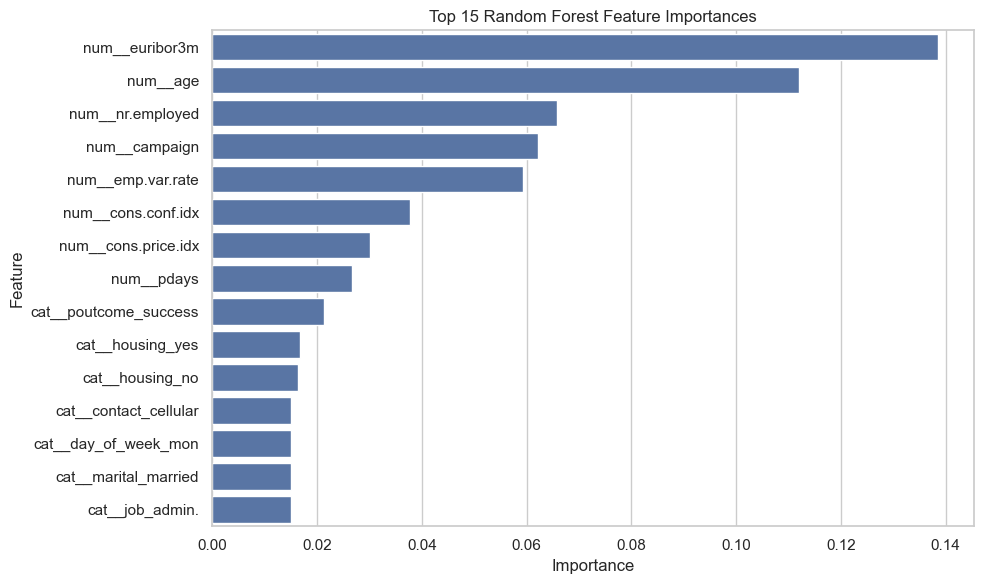

In [19]:
rf_classifier = random_forest_model.named_steps["classifier"]
rf_preprocessor = random_forest_model.named_steps["preprocessing"]
try:
    feature_names = rf_preprocessor.get_feature_names_out()
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": rf_classifier.feature_importances_
    }).sort_values("Importance", ascending=False).head(15)
    display(importance_df)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title("Top 15 Random Forest Feature Importances")
    plt.tight_layout()
    plt.show()
except Exception as error:
    print("Could not display feature importance:", error)

## 17. Save test-set predictions

In [20]:
predictions = X_test.copy()
predictions["Actual_Subscription"] = y_test.map({0: "no", 1: "yes"})
predictions["Predicted_Subscription"] = pd.Series(best_y_pred, index=X_test.index).map({0: "no", 1: "yes"})
predictions["Predicted_Probability_Yes"] = best_y_prob
predictions.to_csv("bank_marketing_test_predictions.csv", index=False)
print("Saved: bank_marketing_test_predictions.csv")
display(predictions.head())

Saved: bank_marketing_test_predictions.csv


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,Actual_Subscription,Predicted_Subscription,Predicted_Probability_Yes
8489,35,services,married,high.school,unknown,no,no,telephone,jun,wed,...,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no,no,0.184768
40832,30,student,single,professional.course,no,yes,no,cellular,sep,tue,...,1,success,-1.1,94.199,-37.5,0.880,4963.6,yes,yes,0.957535
35671,37,self-employed,single,basic.4y,no,yes,no,cellular,may,mon,...,1,failure,-1.8,92.893,-46.2,1.244,5099.1,no,no,0.307801
35984,31,blue-collar,single,professional.course,no,no,no,cellular,may,tue,...,0,nonexistent,-1.8,92.893,-46.2,1.266,5099.1,no,no,0.449034
21954,31,technician,married,university.degree,no,unknown,unknown,cellular,aug,wed,...,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,no,no,0.337090


## 18. Save the selected model

In [21]:
joblib.dump(best_model, "bank_marketing_best_model.joblib")
print("Saved: bank_marketing_best_model.joblib")
print("Selected model:", best_model_name)

Saved: bank_marketing_best_model.joblib
Selected model: Logistic Regression


## 19. Final summary

In [22]:
print("=" * 65)
print("WEEK 4: BANK TERM DEPOSIT SUBSCRIPTION PREDICTION")
print("=" * 65)
print("Dataset rows:", len(df))
print("Input features:", X.shape[1])
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Selected model:", best_model_name)
print("\nCross-validation results:")
display(cv_summary.round(4))
print("\nTest-set comparison:")
display(test_summary.round(4))
print("\nGenerated files:")
print("- bank_marketing_test_predictions.csv")
print("- bank_marketing_best_model.joblib")

WEEK 4: BANK TERM DEPOSIT SUBSCRIPTION PREDICTION
Dataset rows: 41176
Input features: 19
Training records: 32940
Testing records: 8236
Selected model: Logistic Regression

Cross-validation results:


,CV ROC-AUC Mean,CV ROC-AUC Std,CV Average Precision Mean,CV F1 Mean
Logistic Regression,0.7899,0.0029,0.4447,0.4500
Random Forest,0.7823,0.0044,0.4482,0.4822



Test-set comparison:


,Accuracy,Balanced Accuracy,Precision (yes),Recall (yes),F1-score (yes),ROC-AUC,Average Precision
Model,,,,,,,
Logistic Regression,0.8303,0.7496,0.3591,0.6455,0.4615,0.8002,0.4463
Random Forest,0.8866,0.7141,0.4967,0.4914,0.4940,0.7983,0.4716



Generated files:
- bank_marketing_test_predictions.csv
- bank_marketing_best_model.joblib


## 20. Discussion points for the final report

Use your notebook's actual outputs to discuss:
1. **Class imbalance:** Explain why accuracy alone can be misleading when `yes` outcomes are less common.
2. **Duration exclusion:** Explain why call duration was excluded for a realistic pre-call prediction.
3. **Preprocessing:** Describe numerical imputation/scaling and categorical imputation/one-hot encoding.
4. **Model comparison:** Compare Logistic Regression and Random Forest using cross-validation and test metrics.
5. **Error analysis:** Use the confusion matrix to discuss false positives and false negatives.
6. **Limitations:** The results depend on this dataset, chosen features, split and modelling decisions. Metrics do not guarantee real-world campaign success.

**Do not invent performance values.** Use only the metrics printed by your own run.

## References
- UCI Machine Learning Repository: Bank Marketing dataset.
- Scikit-learn documentation for pipelines, preprocessing, classification models and evaluation metrics.

**Reproducibility:** Random state is set to 42. Keep `bank_marketing_cleaned.csv` in the same folder as this notebook.

In [23]:
import os

files = [
    "bank_marketing_test_predictions.csv",
    "bank_marketing_best_model.joblib"
]

for file in files:
    if os.path.exists(file):
        print(file, "— Saved successfully")
        print("File size:", os.path.getsize(file), "bytes")
    else:
        print(file, "— NOT FOUND")

bank_marketing_test_predictions.csv — Saved successfully
File size: 1137005 bytes
bank_marketing_best_model.joblib — Saved successfully
File size: 7610 bytes
